# **Assignment 5**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [1]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
import xgboost as xgb

In [24]:
# Load dataset
data = pd.read_csv("datasets/wine_quality.csv")

data = data.iloc[:, 2:]
data['alcohol_level'] = data['alcohol_level'].apply(lambda x: 1 if x == "high" else 0)
data['quality'] = data['quality'].apply(lambda x: 1 if x == "high" else 0)

# Split features and target
X = data.drop('quality', axis=1)
y = data['quality']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [25]:
data.head()

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,quality,alcohol_level
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,0,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,0,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,0,1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,0,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,0,0


In [26]:

# Gradient Boosting from Scratch
class GradientBoostingFromScratch:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []
        self.initial_prediction = None

    def fit(self, X, y):
        # Initialize with the mean of the target (baseline prediction)
        self.initial_prediction = y.mode()[0]
        residual = y.apply(lambda v: 1 if v != self.initial_prediction else 0)  # Initialize residuals

        for _ in range(self.n_estimators):
            # Fit a weak learner (regression tree) on residuals
            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=42)
            tree.fit(X, residual)
            predictions = tree.predict(X)

            # Update residuals
            residual -= self.learning_rate * predictions

            self.trees.append(tree)

    def predict(self, X):
        # Start with the initial prediction (constant value)
        predictions = np.full(X.shape[0], self.initial_prediction, dtype=float)
        
        # Add contributions from each tree
        for tree in self.trees:
            predictions += self.learning_rate * tree.predict(X)
        
        # Convert to binary (0 or 1) for binary classification
        return np.round(predictions).astype(int)  # Round to get 0 or 1 predictions


In [27]:
# Train the gradient boosting model
gb_model = GradientBoostingFromScratch(n_estimators=50, learning_rate=0.1, max_depth=2)
gb_model.fit(X_train, y_train)

# Predictions
y_pred_train = gb_model.predict(X_train)
y_pred_test = gb_model.predict(X_test)

In [28]:
# Accuracy
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")

Training Accuracy: 0.82
Test Accuracy: 0.79


In [29]:
# Evaluate performance with different parameters
for depth in [1, 2, 3]:
    for lr in [0.05, 0.1, 0.2]:
        gb_model = GradientBoostingFromScratch(n_estimators=50, learning_rate=lr, max_depth=depth)
        gb_model.fit(X_train, y_train)
        y_pred_test = gb_model.predict(X_test)
        test_accuracy = accuracy_score(y_test, y_pred_test)
        print(f"Max Depth: {depth}, Learning Rate: {lr}, Test Accuracy: {test_accuracy:.2f}")

Max Depth: 1, Learning Rate: 0.05, Test Accuracy: 0.77
Max Depth: 1, Learning Rate: 0.1, Test Accuracy: 0.77
Max Depth: 1, Learning Rate: 0.2, Test Accuracy: 0.78
Max Depth: 2, Learning Rate: 0.05, Test Accuracy: 0.77
Max Depth: 2, Learning Rate: 0.1, Test Accuracy: 0.79
Max Depth: 2, Learning Rate: 0.2, Test Accuracy: 0.80
Max Depth: 3, Learning Rate: 0.05, Test Accuracy: 0.79
Max Depth: 3, Learning Rate: 0.1, Test Accuracy: 0.81
Max Depth: 3, Learning Rate: 0.2, Test Accuracy: 0.83


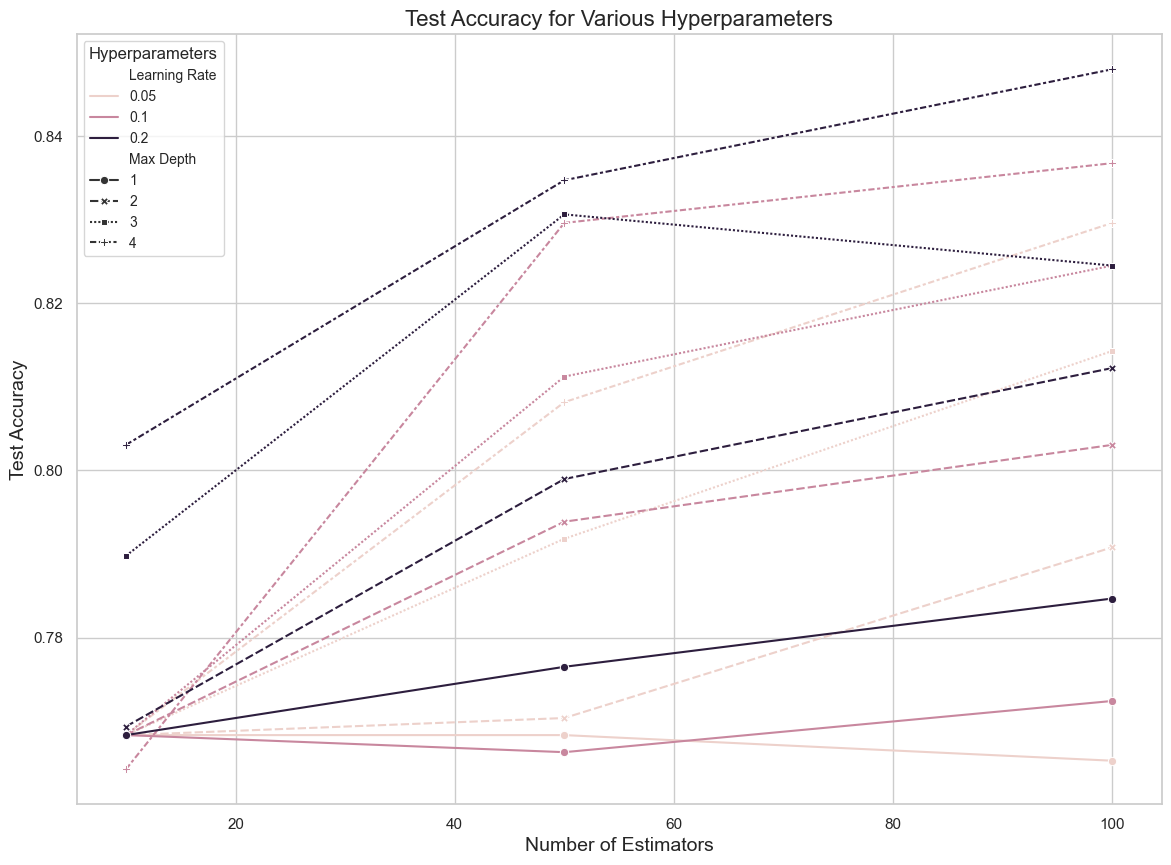

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Function to evaluate and visualize performance
def evaluate_and_visualize(X_train, y_train, X_test, y_test):
    depths = [1, 2, 3, 4]
    learning_rates = [0.05, 0.1, 0.2]
    n_estimators_list = [10, 50, 100]

    results = []

    for depth in depths:
        for lr in learning_rates:
            for n_estimators in n_estimators_list:
                gb_model = GradientBoostingFromScratch(
                    n_estimators=n_estimators,
                    learning_rate=lr,
                    max_depth=depth,
                )
                gb_model.fit(X_train, y_train)
                y_pred_train = gb_model.predict(X_train)
                y_pred_test = gb_model.predict(X_test)

                train_accuracy = accuracy_score(y_train, y_pred_train)
                test_accuracy = accuracy_score(y_test, y_pred_test)

                results.append({
                    "Max Depth": depth,
                    "Learning Rate": lr,
                    "N Estimators": n_estimators,
                    "Train Accuracy": train_accuracy,
                    "Test Accuracy": test_accuracy,
                })

    # Convert results to a DataFrame
    results_df = pd.DataFrame(results)

    # Visualize the results
    sns.set(style="whitegrid")
    plt.figure(figsize=(14, 10))
    sns.lineplot(
        data=results_df,
        x="N Estimators",
        y="Test Accuracy",
        hue="Learning Rate",
        style="Max Depth",
        markers=True,
    )
    plt.title("Test Accuracy for Various Hyperparameters", fontsize=16)
    plt.xlabel("Number of Estimators", fontsize=14)
    plt.ylabel("Test Accuracy", fontsize=14)
    plt.legend(title="Hyperparameters", fontsize=10)
    plt.show()

# Run the evaluation and visualization
evaluate_and_visualize(X_train, y_train, X_test, y_test)


In [31]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Train the custom GradientBoostingFromScratch model
gb_model = GradientBoostingFromScratch(n_estimators=50, learning_rate=0.1, max_depth=2)
gb_model.fit(X_train, y_train)

# 2. Train the GradientBoostingClassifier from scikit-learn
sklearn_gb_model = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=42)
sklearn_gb_model.fit(X_train, y_train)

# 3. Predictions from both models
y_pred_train_custom = gb_model.predict(X_train)
y_pred_test_custom = gb_model.predict(X_test)

y_pred_train_sklearn = sklearn_gb_model.predict(X_train)
y_pred_test_sklearn = sklearn_gb_model.predict(X_test)

# 4. Evaluate the performance
print("Custom Model (Train):")
print(classification_report(y_train, y_pred_train_custom))

print("Custom Model (Test):")
print(classification_report(y_test, y_pred_test_custom))

print("Scikit-learn Model (Train):")
print(classification_report(y_train, y_pred_train_sklearn))

print("Scikit-learn Model (Test):")
print(classification_report(y_test, y_pred_test_sklearn))

# 5. Compare Accuracy (you can use other metrics as well)
train_accuracy_custom = accuracy_score(y_train, y_pred_train_custom)
test_accuracy_custom = accuracy_score(y_test, y_pred_test_custom)

train_accuracy_sklearn = accuracy_score(y_train, y_pred_train_sklearn)
test_accuracy_sklearn = accuracy_score(y_test, y_pred_test_sklearn)

print(f"Custom Model Accuracy (Train): {train_accuracy_custom}")
print(f"Custom Model Accuracy (Test): {test_accuracy_custom}")
print(f"Scikit-learn Model Accuracy (Train): {train_accuracy_sklearn}")
print(f"Scikit-learn Model Accuracy (Test): {test_accuracy_sklearn}")


Custom Model (Train):
              precision    recall  f1-score   support

           0       0.82      0.99      0.90      3085
           1       0.80      0.22      0.34       833

    accuracy                           0.82      3918
   macro avg       0.81      0.60      0.62      3918
weighted avg       0.82      0.82      0.78      3918

Custom Model (Test):
              precision    recall  f1-score   support

           0       0.80      0.97      0.88       753
           1       0.70      0.19      0.30       227

    accuracy                           0.79       980
   macro avg       0.75      0.58      0.59       980
weighted avg       0.78      0.79      0.75       980

Scikit-learn Model (Train):
              precision    recall  f1-score   support

           0       0.83      0.98      0.90      3085
           1       0.76      0.28      0.41       833

    accuracy                           0.83      3918
   macro avg       0.80      0.63      0.66      3918
wei

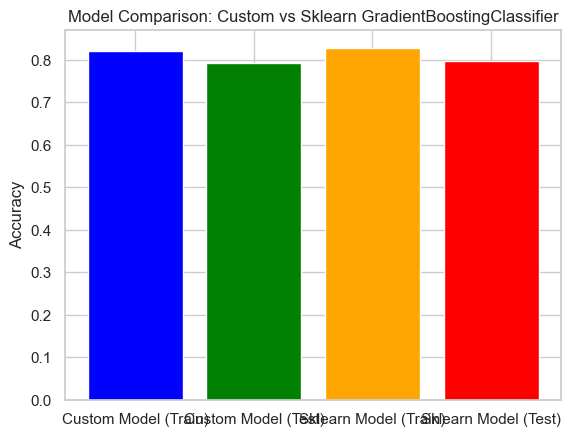

In [32]:
import matplotlib.pyplot as plt

# Plot accuracy comparison
labels = ['Custom Model (Train)', 'Custom Model (Test)', 'Sklearn Model (Train)', 'Sklearn Model (Test)']
accuracies = [train_accuracy_custom, test_accuracy_custom, train_accuracy_sklearn, test_accuracy_sklearn]

plt.bar(labels, accuracies, color=['blue', 'green', 'orange', 'red'])
plt.ylabel('Accuracy')
plt.title('Model Comparison: Custom vs Sklearn GradientBoostingClassifier')
plt.show()


In [33]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report

# 1. Train the custom GradientBoostingFromScratch model
gb_model = GradientBoostingFromScratch(n_estimators=50, learning_rate=0.1, max_depth=2)
gb_model.fit(X_train, y_train)

# 2. Train the GradientBoostingClassifier from scikit-learn
sklearn_gb_model = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=42)
sklearn_gb_model.fit(X_train, y_train)

# 3. Train the XGBoost model
xgboost_model = xgb.XGBClassifier(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=42)
xgboost_model.fit(X_train, y_train)

# 4. Predictions from all three models
y_pred_train_custom = gb_model.predict(X_train)
y_pred_test_custom = gb_model.predict(X_test)

y_pred_train_sklearn = sklearn_gb_model.predict(X_train)
y_pred_test_sklearn = sklearn_gb_model.predict(X_test)

y_pred_train_xgboost = xgboost_model.predict(X_train)
y_pred_test_xgboost = xgboost_model.predict(X_test)

# 5. Evaluate the performance
print("Custom Model (Train):")
print(classification_report(y_train, y_pred_train_custom))

print("Custom Model (Test):")
print(classification_report(y_test, y_pred_test_custom))

print("Scikit-learn Model (Train):")
print(classification_report(y_train, y_pred_train_sklearn))

print("Scikit-learn Model (Test):")
print(classification_report(y_test, y_pred_test_sklearn))

print("XGBoost Model (Train):")
print(classification_report(y_train, y_pred_train_xgboost))

print("XGBoost Model (Test):")
print(classification_report(y_test, y_pred_test_xgboost))

# 6. Compare Accuracy
train_accuracy_custom = accuracy_score(y_train, y_pred_train_custom)
test_accuracy_custom = accuracy_score(y_test, y_pred_test_custom)

train_accuracy_sklearn = accuracy_score(y_train, y_pred_train_sklearn)
test_accuracy_sklearn = accuracy_score(y_test, y_pred_test_sklearn)

train_accuracy_xgboost = accuracy_score(y_train, y_pred_train_xgboost)
test_accuracy_xgboost = accuracy_score(y_test, y_pred_test_xgboost)

print(f"Custom Model Accuracy (Train): {train_accuracy_custom}")
print(f"Custom Model Accuracy (Test): {test_accuracy_custom}")
print(f"Scikit-learn Model Accuracy (Train): {train_accuracy_sklearn}")
print(f"Scikit-learn Model Accuracy (Test): {test_accuracy_sklearn}")
print(f"XGBoost Model Accuracy (Train): {train_accuracy_xgboost}")
print(f"XGBoost Model Accuracy (Test): {test_accuracy_xgboost}")


Custom Model (Train):
              precision    recall  f1-score   support

           0       0.82      0.99      0.90      3085
           1       0.80      0.22      0.34       833

    accuracy                           0.82      3918
   macro avg       0.81      0.60      0.62      3918
weighted avg       0.82      0.82      0.78      3918

Custom Model (Test):
              precision    recall  f1-score   support

           0       0.80      0.97      0.88       753
           1       0.70      0.19      0.30       227

    accuracy                           0.79       980
   macro avg       0.75      0.58      0.59       980
weighted avg       0.78      0.79      0.75       980

Scikit-learn Model (Train):
              precision    recall  f1-score   support

           0       0.83      0.98      0.90      3085
           1       0.76      0.28      0.41       833

    accuracy                           0.83      3918
   macro avg       0.80      0.63      0.66      3918
wei